# Final four-architecture Lottery Ticket Hypothesis experiment

## 1. Research question

**How does the ratio between hidden-layer widths affect the accuracy and trainability of winning tickets when the total number of parameters is held approximately constant?**

The Lottery Ticket Hypothesis proposes that dense networks contain sparse subnetworks which can train effectively from their original initialization. We reimplement the Appendix G.1 methodology of Frankle and Carbin (2019) and extend the Appendix G.6 network-size investigation to four fixed width allocations near 200k dense parameters.

This notebook describes a **fresh, uniform four-architecture run**, not a mixture of old A/B/C models and a new D. It contains 156 original-initialization training stages and all-stage selected-state test evaluation. No new random-reinitialization controls are run.

**The MNIST test set was examined in the previous study. This is an exploratory extension on that established test set, not an independent unseen confirmation of D.** Architecture widths and the entire protocol were fixed before training.

Default saved mode imports reusable tested modules, verifies numerical CSVs, and regenerates the figure without training, data downloads, tensor loading, or test reevaluation.

## 2. Four fixed network architectures

All models have 784 inputs, two ReLU hidden layers, and ten output logits. Biases start at zero and remain unpruned. Gaussian Glorot initialization uses gain 1. Dense parameter counts include biases and are verified programmatically; the 121-parameter spread is 0.0605% of 200k.

In [1]:
MODE = "saved"
ENABLE_TRAINING = False
REPRODUCTION_RUN_DIR = "artifacts/reproduction_01"

import os,tempfile,json,inspect
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR",str(Path(tempfile.gettempdir())/"four-architecture-mpl"))
import pandas as pd
from IPython.display import display,Image,Markdown
from study import ROOT,COUNTS,config
from models import ARCHITECTURES,MLP,parameter_count
from analysis import reproduce_saved,finalize
if MODE not in ("saved","reproduce"): raise ValueError("Choose saved or reproduce mode explicitly")
if MODE=="saved" and ENABLE_TRAINING: raise PermissionError("Saved mode cannot enable training")
architectures=pd.DataFrame([dict(architecture=a,hidden1=w[0],hidden2=w[1],width_ratio=w[0]/w[1],parameters=parameter_count(MLP(*w))) for a,w in ARCHITECTURES.items()])
assert dict(zip(architectures.architecture,architectures.parameters))==COUNTS
display(architectures)

,architecture,hidden1,hidden2,width_ratio,parameters
0,A,162,421,0.384798,200013
1,B,200,204,0.980392,200054
2,C,231,77,3.000000,199979
3,D,242,40,6.050000,200100


## 3. Experimental protocol

MNIST: **55,000 train / 5,000 validation / 10,000 test**, split seed **42**, model seeds **0,1,2**. Adam **.0012**, batch **60**, cross-entropy. Each stage trains for **10,000 fixed updates**, validating every **100**. There are **12 pruning rounds plus dense**, giving 4 × 3 × 13 = **156 training stages**.

All 156 checkpoint selections are fixed using validation alone, and each actual saved state must reproduce its recorded validation loss and accuracy before any new-study test forward pass. All 13 stages per architecture/seed are then tested on all 10,000 test images. There is no test-driven architecture choice, tuning or stopping rule. Ten thousand updates is a reduced budget relative to the original paper's 50,000.

In [2]:
display(config())
if MODE=="saved":
    display(json.loads((ROOT/"results/protocol.json").read_text())["versions"])

{'architectures': {'A': [162, 421],
  'B': [200, 204],
  'C': [231, 77],
  'D': [242, 40]},
 'model_seeds': [0, 1, 2],
 'split_seed': 42,
 'training_examples': 55000,
 'validation_examples': 5000,
 'test_examples': 10000,
 'initialization': 'gaussian_glorot',
 'bias_initialization': 'zero',
 'optimizer': 'Adam',
 'learning_rate': 0.0012,
 'batch_size': 60,
 'iterations': 10000,
 'validation_interval': 100,
 'pruning_rounds': 12,
 'hidden_pruning_rate': 0.2,
 'output_pruning_rate': 0.1,
 'biases_pruned': False,
 'device': 'cpu',
 'num_threads': 1,
 'controls': False,
 'test_stages': 'all'}

{'torch': '2.6.0+cpu',
 'torchvision': '0.21.0+cpu',
 'numpy': '2.5.4',
 'pandas': '2.3.3',
 'matplotlib': '3.11.2'}

## 4. Iterative magnitude pruning and separate checkpoint states

Prune floor(20% of current hidden-layer survivors) and floor(10% of output survivors) independently by layer. Masks are monotone; biases stay dense. Restore survivors and biases to **exact original initialization**; create fresh Adam. The validated training code masks gradients and reapplies masks after every update.

Two states are deliberately saved:

1. **Final 10k state:** determines the next magnitude-pruning mask.
2. **Best-validation state:** an actual snapshot on strict loss improvement; used for reporting/test evaluation. Exact ties retain the first iteration.

Minimum-validation-loss iteration is retrospective selection, **not early stopping**. The core implementations below are imported from the tested modules rather than duplicated. No pruning or training operation runs in this display cell.

In [3]:
from pruning import prune_masks,rewind_weights
from train import train_stage
print(inspect.getsource(prune_masks))
print(inspect.getsource(rewind_weights))
print("Training API:",inspect.signature(train_stage))

@torch.no_grad()
def prune_masks(
    model: nn.Module,
    masks: Mapping[str, Tensor],
    hidden_rate: float = 0.2,
    output_rate: float = 0.1,
) -> dict[str, Tensor]:
    """Return new masks, dropping floor(rate * active_count) weights per layer.

    Previously removed entries remain removed. Stable sorting resolves equal
    magnitudes by flattened weight index, ensuring deterministic tie-breaking.
    The last Linear layer is the output layer. Neither input masks nor trained
    parameters are modified, so callers may save them before rewinding.
    """
    for rate in (hidden_rate, output_rate):
        if not math.isfinite(rate) or not 0.0 <= rate <= 1.0:
            raise ValueError("Pruning rates must be finite fractions between 0 and 1.")
    layers = _validate_masks(model, masks)
    output_name = next(reversed(layers))
    result: dict[str, Tensor] = {}
    for name, layer in layers.items():
        mask = masks[name].to(layer.weight.device).clone()
        flat_mask = 

## 5. Training and complete validation histories

Saved mode reads the verified final measurements. Full reproduction is separate and requires **both** explicit settings. It uses a new directory under `artifacts/` and writes analysis under `reproductions/`; this notebook refuses to use the verified primary run as a reproduction destination. Completed training stages resume by checksummed commits; partial stages restart from their prescribed masked initialization with fresh Adam.

A full reproduction trains all 156 stages, saves actual best states during training, gates all selections before testing, and performs no random controls. See the README for runtime and storage estimates.

In [4]:
DATA_ROOT=ROOT
if MODE=="reproduce":
    if ENABLE_TRAINING is not True: raise PermissionError("Explicit ENABLE_TRAINING=True is required")
    if Path(REPRODUCTION_RUN_DIR).name=="main_study": raise ValueError("Choose a separate reproduction run name")
    from study import execute
    execute(REPRODUCTION_RUN_DIR,workers=3,enable_training=True,download=True)
    DATA_ROOT=ROOT/"reproductions"/Path(REPRODUCTION_RUN_DIR).name
    individual,aggregated=finalize(REPRODUCTION_RUN_DIR,output=DATA_ROOT)
else:
    individual,aggregated=reproduce_saved(ROOT)
history=pd.read_csv(DATA_ROOT/"results/validation_history.csv")
assert len(history)==15600
sizes=history.groupby(["architecture","model_seed","pruning_stage"]).size()
assert len(sizes)==156 and sizes.eq(100).all()
display(history.groupby("architecture").agg(observations=("iteration","size"),first_update=("iteration","min"),last_update=("iteration","max")))
display(history.head(8))

,observations,first_update,last_update
architecture,,,
A,3900,100,10000
B,3900,100,10000
C,3900,100,10000
D,3900,100,10000


,iteration,selection_eligible,training_loss,validation_loss,validation_accuracy,architecture,model_seed,pruning_stage
0,100,True,0.293789,0.353494,0.8956,A,0,0
1,200,True,0.235169,0.261275,0.9216,A,0,0
2,300,True,0.212944,0.207204,0.9342,A,0,0
3,400,True,0.105615,0.195290,0.9402,A,0,0
4,500,True,0.118382,0.175314,0.9448,A,0,0
5,600,True,0.196012,0.144159,0.9564,A,0,0
6,700,True,0.341351,0.147062,0.9554,A,0,0
7,800,True,0.102858,0.138439,0.9580,A,0,0


## 6. Held-out test accuracy at every observed stage

All **156** test results correspond to actual saved minimum-validation-loss checkpoints. They are not interpolated values, final-weight substitutions, or historical checkpoint replays. Tests occurred only after all selections were fixed and verified. Earlier 16k/20k interpolated validation estimates are not part of this new dataset.

`active_parameters` includes dense biases. `remaining_weight_percentage` and `weight_sparsity` exclude biases; `parameter_sparsity` includes them. Different architectures have slightly different surviving counts at the same pruning round. Individual-seed and aggregate results are retained in the CSVs.

In [5]:
assert len(individual)==156 and len(aggregated)==52
assert individual.test_examples.eq(10000).all() and individual.verified.eq(True).all()
display(individual[["architecture","model_seed","pruning_stage","active_parameters","remaining_weight_percentage","iteration_min_validation_loss","validation_accuracy","test_accuracy","test_accuracy_change_pp"]].head(16))
display(aggregated[["architecture","pruning_stage","active_parameters","remaining_weight_percentage","iteration_min_validation_loss_mean","iteration_min_validation_loss_std","test_accuracy_mean","test_accuracy_std"]])

,architecture,model_seed,pruning_stage,active_parameters,remaining_weight_percentage,iteration_min_validation_loss,validation_accuracy,test_accuracy,test_accuracy_change_pp
0,A,0,0,200013,100.000000,2500,0.9786,0.9780,0.00
1,A,0,1,160551,80.211614,2300,0.9762,0.9769,-0.11
2,A,0,2,128940,64.360144,2600,0.9820,0.9785,0.05
3,A,0,3,103612,51.659312,2600,0.9812,0.9806,0.26
4,A,0,4,83316,41.481797,2500,0.9796,0.9805,0.25
5,A,0,5,67049,33.324641,2300,0.9816,0.9811,0.31
6,A,0,6,54008,26.785177,2600,0.9810,0.9818,0.38
7,A,0,7,43550,21.540969,1900,0.9814,0.9812,0.32
8,A,0,8,35162,17.334771,2500,0.9820,0.9824,0.44
9,A,0,9,28431,13.959482,2500,0.9814,0.9821,0.41


,architecture,pruning_stage,active_parameters,remaining_weight_percentage,iteration_min_validation_loss_mean,iteration_min_validation_loss_std,test_accuracy_mean,test_accuracy_std
0,A,0,200013,100.000000,4300.000000,1637.070554,0.979233,0.001124
1,A,1,160551,80.211614,3400.000000,964.365076,0.978933,0.002281
2,A,2,128940,64.360144,2400.000000,529.150262,0.979567,0.001007
3,A,3,103612,51.659312,2066.666667,472.581563,0.980033,0.000737
4,A,4,83316,41.481797,2200.000000,360.555128,0.981167,0.000987
5,A,5,67049,33.324641,2166.666667,230.940108,0.981100,0.000100
6,A,6,54008,26.785177,2266.666667,351.188458,0.981700,0.000361
7,A,7,43550,21.540969,2033.333333,230.940108,0.981733,0.000503
8,A,8,35162,17.334771,1966.666667,472.581563,0.981200,0.001039
9,A,9,28431,13.959482,2366.666667,416.333200,0.981300,0.000917


## 7. Main two-panel figure

Each panel contains **52 actual observed stage means** (4 × 13). Error bars are **sample SD (ddof=1) across three seeds**, not confidence intervals. Markers identify measurements; lines connect adjacent observations only. The reversed logarithmic x-axis ends near the actual final remaining-weight percentages, not 1%. The dotted horizontal line marks the common 10k-update training budget.

The figure is saved as a vector PDF and 600-dpi PNG at approximately two-column paper width. Numerical values and the concise caption are saved alongside the final results.

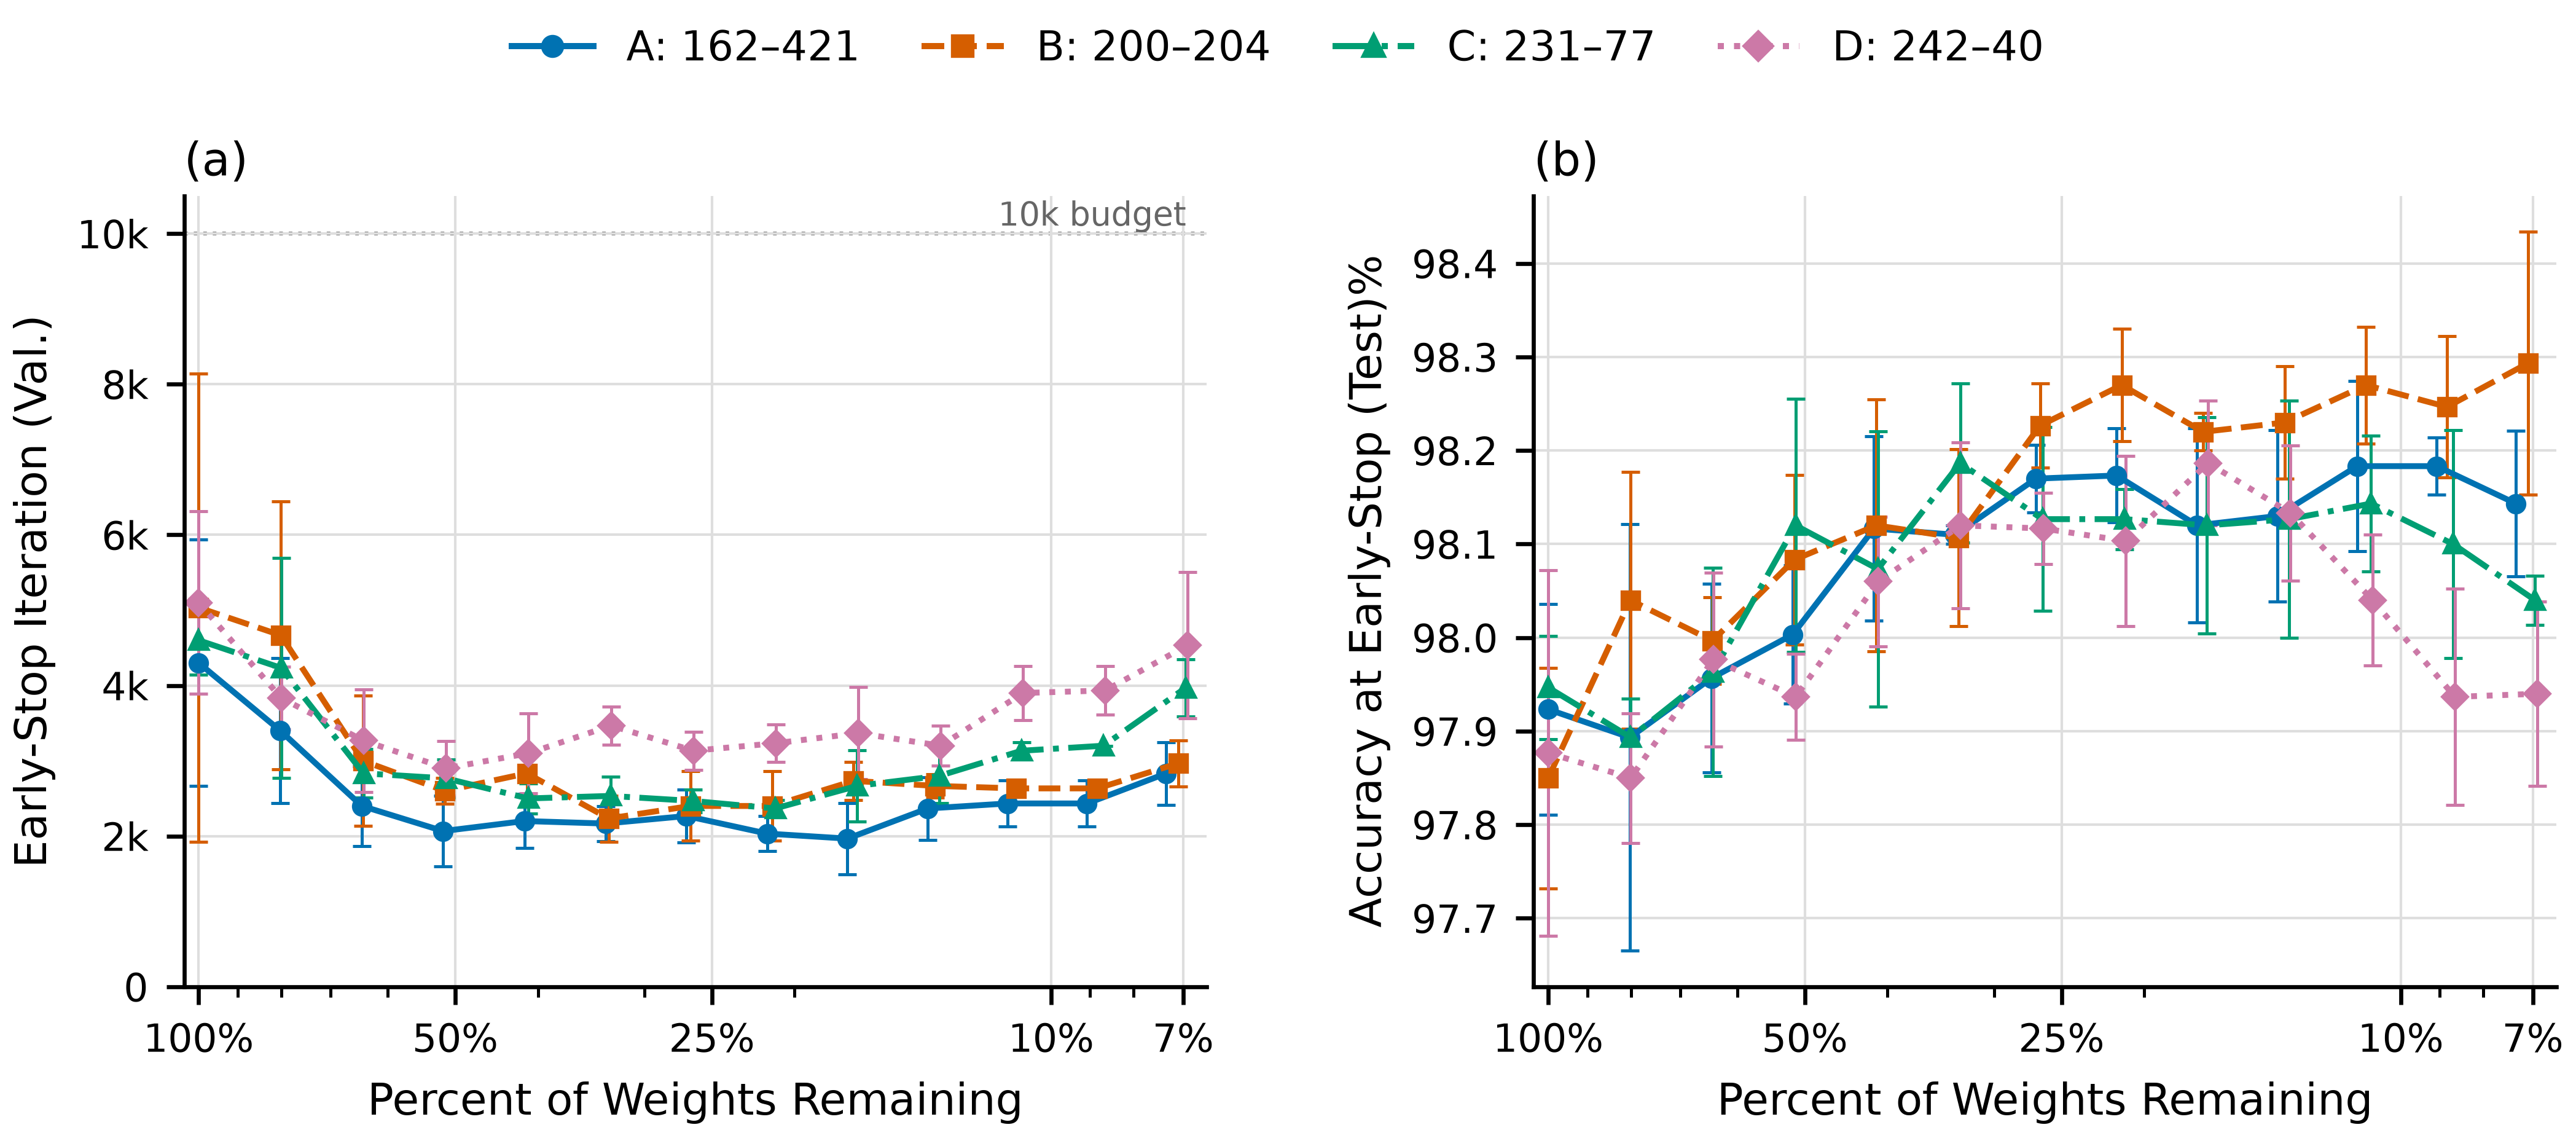

Four fixed approximately 200k-parameter MNIST MLPs across 12 iterative pruning rounds plus the dense stage. (a) Iteration of minimum validation loss; the dotted line marks the fixed 10,000-update training budget. (b) Test accuracy of the corresponding validation-selected state. The axis wording follows the original paper: 'Early-Stop' denotes retrospective minimum-validation-loss selection, not actual early termination; every model received all 10,000 updates. Every architecture has all 13 observed stages, aggregated over model seeds 0, 1 and 2; error bars show sample standard deviation. The reversed logarithmic x-axis uses actual percentages of original mask-active weights remaining, excluding biases. Lines join observed points only. Checkpoint selection was fixed and verified before test evaluation. This is an exploratory extension using the previously examined MNIST test set, not an independent unseen confirmation.


In [6]:
display(Image(filename=str(DATA_ROOT/"paper_assets/main_results.png")))
display(Markdown((DATA_ROOT/"paper_assets/main_results_caption.txt").read_text()))

## 8. Numerical findings, verification and limitations

Interpret the four complete trajectories and the individual seeds, not just the highest point at a selected stage. Descriptive stage-average/ranking summaries do not turn dependent pruning stages into extra independent replicates. The findings below are generated from this new run's actual measurements.

Only three seeds, one dataset/split, approximate dense budgets and unequal surviving counts were studied. Mask geometry also differs. The 10k budget may limit some trajectories; minimum-loss iteration is not a convergence proof. The test set was previously examined, so this is exploratory. No statistically significant universally superior ratio is established. No new random controls were run or mixed into this study.

In [7]:
display(Markdown((DATA_ROOT/"results/findings.md").read_text()))
verification=json.loads((DATA_ROOT/"results/verification.json").read_text())
display({k:v for k,v in verification.items() if k not in ("selected_checkpoint_sha256","source_sha256")})
# Recheck saved numerical integrity. This only redraws the main figure.
checked,checked_summary=reproduce_saved(DATA_ROOT)
assert len(checked)==156 and len(checked_summary)==52
print("Saved measurements verified; no training, checkpoint reselection or test reevaluation in saved mode.")

Saved measurements verified; no training, checkpoint reselection or test reevaluation in saved mode.


# Four-architecture exploratory findings

This new study freshly trained **156 stages**: four fixed architectures × three model seeds × 13 observed stages. Every stage received 10,000 Adam updates with 100-update validation. All 156 actual best-validation states passed reload validation before all-stage test evaluation. No historical A/B/C checkpoint or random-control measurement was substituted, and no new random-reinitialization controls were run.

The main figure shows complete observed trajectories of minimum-validation-loss iteration and held-out test accuracy against each architecture's actual remaining-weight percentage. Lines join observed means; bars are **sample SD across three seeds**, not confidence intervals. Identical pruning rounds do not have exactly equal remaining counts.

| Architecture | Dense mean test (%) | Stage 12 test (%) | Stage 12 change from own dense (pp) | Stage 12 selected iteration | Stage 12 active parameters |
|---|---:|---:|---:|---:|---:|
| A | 97.923 | 98.143 ± 0.078 | +0.220 ± 0.182 | 2833 ± 416 | 15,203 |
| B | 97.850 | 98.293 ± 0.140 | +0.443 ± 0.202 | 2967 ± 306 | 14,575 |
| C | 97.947 | 98.040 ± 0.026 | +0.093 ± 0.067 | 3967 ± 379 | 14,209 |
| D | 97.877 | 97.940 ± 0.098 | +0.063 ± 0.172 | 4533 ± 971 | 14,115 |

Across the full trajectories, the observed between-architecture mean test-accuracy spread ranged from **0.040 to 0.353 percentage points**, depending on stage. This describes magnitude, not statistical significance or equal-count comparison.

| Architecture | Range of observed stage-mean test accuracy (%) | Mean across 12 pruned stage means (%) | Pruned stages with nonnegative mean dense-relative change |
|---|---:|---:|---:|
| A | 97.893–98.183 | 98.099 | 11/12 |
| B | 97.850–98.293 | 98.175 | 12/12 |
| C | 97.893–98.187 | 98.085 | 11/12 |
| D | 97.850–98.187 | 98.033 | 11/12 |

Across the **13 observed stage means**, counts of highest mean test accuracy were A: 0/13, B: 10/13, C: 3/13, D: 0/13 (ties count for each tied architecture). This is a descriptive trajectory summary, not 13 independent statistical replications. `trajectory_summary.csv` also reports the range of stage means and the arithmetic mean across the 12 pruned-stage means, which weights pruning rounds equally rather than matching parameter counts. Interpret these alongside the full curves and individual-seed CSV, not as proof of architectural superiority from a selected point.

Width allocation can show different observed accuracy and minimum-loss-iteration trajectories. Their practical size is expressed directly in percentage-point changes and the three-seed variability; no p-values or statistical-significance claims are made. A later selected minimum does not prove failure to converge, and an earlier minimum is not actual early stopping. All models continued to 10,000 updates. 1/156 stages selected minima in the last 20% of the budget; diagnostic slopes are recorded without changing the protocol.

**This is an exploratory extension using the established, previously examined MNIST test set.** It is not an independent unseen confirmation of architecture D. Architectures and protocol were fixed before training and were not adjusted after test inspection. Only three model seeds, one data split, one dataset and approximately matched dense sizes were studied. A/B/C reuse the prior predefined seeds and split, so old and new runs must not be pooled as additional independent replications. Surviving parameter counts and mask geometry differ. The budget is **10,000 rather than the original paper's 50,000 updates**. No universally superior ratio is statistically established by this design.


{'status': 'verified',
 'training_stages': 156,
 'selected_checkpoints': 156,
 'test_evaluations': 156,
 'original_parameter_counts': {'A': 200013,
  'B': 200054,
  'C': 199979,
  'D': 200100},
 'all_starts_exactly_original': True,
 'all_masks_enforced': True,
 'all_next_masks_from_final_states': True,
 'all_protocols_identical': True,
 'failed_checkpoints_tested': 0,
 'validation_loss_absolute_tolerance': 1e-08,
 'validation_accuracy_absolute_tolerance': 1e-12,
 'max_validation_loss_discrepancy': 0.0,
 'max_validation_accuracy_discrepancy': 0.0,
 'original_artifact_preservation': {'status': 'unchanged',
  'checked': 1382,
  'basis': 'Packaging-time audit of the original study; historical recovery references are in archive/README.md'},
 'new_controls_run': 0,
 'test_set_previously_examined': True,
 'training_wall_seconds': 3176.593716566,
 'versions': {'torch': '2.6.0+cpu',
  'torchvision': '0.21.0+cpu',
  'numpy': '2.5.4',
  'pandas': '2.3.3',
  'matplotlib': '3.11.2'},
 'figure_obser